In [1]:
import pandas as pd
df=pd.read_csv("/content/meditrack_dataset.csv")
print(df)

      PatientID        PatientName         DOB   Phone PrescriptionID  \
0       P000001        James Clyde  12/22/1982 -3832.0       RX000001   
1       P000002        Sean Harris         NaN -4219.0       RX000002   
2       P000003      Andrew Looper    8/7/1995     NaN       RX000003   
3       P000004         Megan Lora   9/10/1985 -5057.0       RX000004   
4       P000005                NaN    9/5/2001 -3090.0       RX000005   
...         ...                ...         ...     ...            ...   
19995   P019996                NaN  10/26/2001 -4615.0       RX019996   
19996   P019997          Eric Azar    2/9/1957 -5385.0       RX019997   
19997   P019998       James Sierra   3/26/2001 -4122.0       RX019998   
19998   P019999  Roosevelt Johnson   10/7/1974 -3384.0       RX019999   
19999   P020000    Kathleen Foster   7/23/1976 -9712.0       RX020000   

      MedicationName Dosage  Quantity    DoctorName  DateIssued  ExpiryDate  \
0        Rivaroxaban   15ml       100  Dr. A

DATA CLEANING

In [3]:
df.info() # short summary of dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PatientID       20000 non-null  object 
 1   PatientName     17952 non-null  object 
 2   DOB             18001 non-null  object 
 3   Phone           18051 non-null  float64
 4   PrescriptionID  20000 non-null  object 
 5   MedicationName  20000 non-null  object 
 6   Dosage          20000 non-null  object 
 7   Quantity        20000 non-null  int64  
 8   DoctorName      20000 non-null  object 
 9   DateIssued      20000 non-null  object 
 10  ExpiryDate      18010 non-null  object 
 11  StockQuantity   18023 non-null  float64
 12  UnitPrice       20000 non-null  float64
 13  TotalAmount     20000 non-null  float64
 14  PaymentStatus   20000 non-null  object 
dtypes: float64(4), int64(1), object(10)
memory usage: 2.3+ MB


In [4]:
df.describe() # statistical or math operations

,Phone,Quantity,StockQuantity,UnitPrice,TotalAmount
count,18051.000000,20000.000000,18023.000000,20000.000000,20000.000000
mean,-6622.381253,67.268750,2488.741830,127.540668,8552.919318
std,2629.686017,52.033013,1452.437948,70.591641,8912.410110
min,-11845.000000,10.000000,0.000000,5.010000,50.600000
25%,-8851.500000,20.000000,1222.000000,66.920000,2044.650000
50%,-6615.000000,60.000000,2491.000000,127.125000,4978.000000
75%,-4349.000000,100.000000,3755.000000,188.540000,12311.550000
max,-1419.000000,180.000000,5000.000000,249.990000,44967.600000


In [5]:
df.head()

,PatientID,PatientName,DOB,Phone,PrescriptionID,MedicationName,Dosage,Quantity,DoctorName,DateIssued,ExpiryDate,StockQuantity,UnitPrice,TotalAmount,PaymentStatus
0,P000001,James Clyde,12/22/1982,-3832.0,RX000001,Rivaroxaban,15ml,100,Dr. Anderson,5/18/2023,NaN,1933.0,13.53,1353.0,Overdue
1,P000002,Sean Harris,NaN,-4219.0,RX000002,Hydrocodone,250mg,90,Dr. Taylor,7/24/2024,7/24/2025,2044.0,82.02,7381.8,Partial
2,P000003,Andrew Looper,8/7/1995,NaN,RX000003,Levothyroxine,20mg,20,Dr. Thomas,7/14/2025,7/14/2026,1414.0,213.94,4278.8,Partial
3,P000004,Megan Lora,9/10/1985,-5057.0,RX000004,Atorvastatin,0.5mg,20,Dr. White,11/7/2025,11/7/2026,1836.0,199.46,3989.2,Cancelled
4,P000005,NaN,9/5/2001,-3090.0,RX000005,Naproxen,500mg,100,Dr. Moore,4/18/2025,4/18/2026,4709.0,133.80,13380.0,Pending


In [6]:
df.tail()

,PatientID,PatientName,DOB,Phone,PrescriptionID,MedicationName,Dosage,Quantity,DoctorName,DateIssued,ExpiryDate,StockQuantity,UnitPrice,TotalAmount,PaymentStatus
19995,P019996,NaN,10/26/2001,-4615.0,RX019996,Tramadol,20mg,30,Dr. Davis,12/27/2025,12/27/2026,2705.0,248.47,7454.10,Partial
19996,P019997,Eric Azar,2/9/1957,-5385.0,RX019997,Pantoprazole,50mg,20,Dr. Davis,10/23/2023,NaN,1924.0,211.71,4234.20,Partial
19997,P019998,James Sierra,3/26/2001,-4122.0,RX019998,Losartan,5mg,30,Dr. Davis,11/28/2025,11/28/2026,NaN,243.29,7298.70,Partial
19998,P019999,Roosevelt Johnson,10/7/1974,-3384.0,RX019999,Lisinopril,2mg,60,Dr. Brown,7/6/2024,7/6/2025,347.0,236.29,14177.40,Pending
19999,P020000,Kathleen Foster,7/23/1976,-9712.0,RX020000,Morphine,500mg,15,Dr. Williams,10/7/2025,10/7/2026,4745.0,22.89,343.35,Partial


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
print(df.to_string) # first 5 and last 5

<bound method DataFrame.to_string of       PatientID        PatientName         DOB   Phone PrescriptionID  \
0       P000001        James Clyde  12/22/1982 -3832.0       RX000001   
1       P000002        Sean Harris         NaN -4219.0       RX000002   
2       P000003      Andrew Looper    8/7/1995     NaN       RX000003   
3       P000004         Megan Lora   9/10/1985 -5057.0       RX000004   
4       P000005                NaN    9/5/2001 -3090.0       RX000005   
...         ...                ...         ...     ...            ...   
19995   P019996                NaN  10/26/2001 -4615.0       RX019996   
19996   P019997          Eric Azar    2/9/1957 -5385.0       RX019997   
19997   P019998       James Sierra   3/26/2001 -4122.0       RX019998   
19998   P019999  Roosevelt Johnson   10/7/1974 -3384.0       RX019999   
19999   P020000    Kathleen Foster   7/23/1976 -9712.0       RX020000   

      MedicationName Dosage  Quantity    DoctorName  DateIssued  ExpiryDate  \
0      

In [9]:
df.shape# for how many rows and columns

(20000, 15)

In [ ]:
df.columns

Index(['PatientID', 'PatientName', 'DOB', 'Phone', 'PrescriptionID',
       'MedicationName', 'Dosage', 'Quantity', 'DoctorName', 'DateIssued',
       'ExpiryDate', 'StockQuantity', 'UnitPrice', 'TotalAmount',
       'PaymentStatus'],
      dtype='object')

In [ ]:
df.dtypes

,0
PatientID,object
PatientName,object
DOB,object
Phone,object
PrescriptionID,object
MedicationName,object
Dosage,object
Quantity,int64
DoctorName,object
DateIssued,object


In [ ]:
df.isnull().sum()

,0
PatientID,0
PatientName,2048
DOB,1999
Phone,1949
PrescriptionID,0
MedicationName,0
Dosage,0
Quantity,0
DoctorName,0
DateIssued,0


In [10]:
# patient name
df["PatientName"] = df["PatientName"].fillna("Unknown")
# phone
df["Phone"] = df["Phone"].fillna("not available")

df["DOB"] = df["DOB"].fillna("Not Available")

df["ExpiryDate"] = df["ExpiryDate"].fillna("Not Available")

df["DateIssued"] = df["DateIssued"].fillna("Not Available")

In [ ]:
# using median
df["StockQuantity"] = df["StockQuantity"].fillna(df["StockQuantity"].median())

In [ ]:
df.isnull().sum()

,0
PatientID,0
PatientName,2048
DOB,1999
Phone,1949
PrescriptionID,0
MedicationName,0
Dosage,0
Quantity,0
DoctorName,0
DateIssued,0


LIBRARIES

numpy


In [11]:
import numpy as np
stock = np.array(df["StockQuantity"])

In [ ]:
print(np.sum(stock))

49779301.0


In [ ]:
print(np.mean(stock))

2488.96505


In [ ]:
print(np.max(stock))

5000.0


In [ ]:
print(np.min(stock))

0.0


In [ ]:
print(np.median(stock))

2491.0


In [ ]:
print(np.std(stock))

1378.7455828863053


In [12]:
total= np.array(df["TotalAmount"])
print(np.sum(total))
print(np.mean(total))
print(np.max(total))
print(np.min(total))
print(np.median(total))
print(np.std(total))

171058386.35
8552.9193175
44967.6
50.6
4978.0
8912.187297128521


PANDAS

In [13]:
df["PatientName"].nunique() # finds the number of patients

16175

In [ ]:
df["MedicationName"].value_counts()

,count
MedicationName,
Atorvastatin,798
Losartan,782
Metformin,776
Naproxen,439
Pantoprazole,432
Lisinopril,426
Insulin,424
Morphine,424
Fluticasone,417


In [ ]:
print(df["StockQuantity"].mean())

2488.96505


In [ ]:
df[df["StockQuantity"] < 50]

,PatientID,PatientName,DOB,Phone,PrescriptionID,MedicationName,Dosage,Quantity,DoctorName,DateIssued,ExpiryDate,StockQuantity,UnitPrice,TotalAmount,PaymentStatus
157,P000158,Judith Ephriam,1958-05-16,+1-984-338-2373,RX000158,Aspirin,10ml,120,Dr. Johnson,2024-01-23,2025-01-22,44.0,105.12,12614.40,Pending
187,P000188,Ethel Todd,1985-03-03,+1-743-258-8362,RX000188,Aspirin,5mg,45,Dr. Martin,2025-07-18,NaN,5.0,137.69,6196.05,Cancelled
559,P000560,Guillermo Higgins,1961-12-16,+1-489-234-4253,RX000560,Insulin,20mg,120,Dr. Jackson,2024-03-14,2025-03-14,26.0,215.00,25800.00,Partial
570,P000571,Jack Clemons,1981-05-14,+1-518-858-6535,RX000571,Losartan,10mg,60,Dr. Moore,2025-04-12,2026-04-12,45.0,173.80,10428.00,Pending
887,P000888,Kimberley Smith,2010-08-20,NaN,RX000888,Hydrochlorothiazide,1g,180,Dr. Smith,2025-06-17,2026-06-17,22.0,207.09,37276.20,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19837,P019838,Sandra Ellis,1956-05-04,+1-854-728-5736,RX019838,Alteplase,10mg,90,Dr. Taylor,2025-11-21,2026-11-21,13.0,193.19,17387.10,Partial
19873,P019874,NaN,1953-08-04,+1-879-221-1344,RX019874,Cetirizine,100mg,180,Dr. Brown,2025-11-03,2026-11-03,44.0,200.34,36061.20,Overdue
19889,P019890,Edward Ephriam,1992-12-21,+1-852-231-5753,RX019890,Januvia,0.5mg,10,Dr. Johnson,2023-08-14,2024-08-13,48.0,198.25,1982.50,Pending
19904,P019905,Alfred Voss,NaN,+1-374-287-9596,RX019905,Aspirin,500mg,15,Dr. Miller,2025-03-10,2026-03-10,43.0,126.82,1902.30,Paid


In [ ]:
df.sort_values("StockQuantity", ascending=False)

,PatientID,PatientName,DOB,Phone,PrescriptionID,MedicationName,Dosage,Quantity,DoctorName,DateIssued,ExpiryDate,StockQuantity,UnitPrice,TotalAmount,PaymentStatus
18511,P018512,Amparo Brooks,1963-02-24,+1-814-120-1113,RX018512,Lisinopril,10ml,15,Dr. Martin,2023-06-08,2024-06-07,5000.0,166.16,2492.4,Overdue
15386,P015387,Omar Hurdle,1957-03-16,+1-435-375-6822,RX015387,Clopidogrel,10mg,180,Dr. Brown,2025-07-09,2026-07-09,5000.0,95.54,17197.2,Paid
356,P000357,Gilbert Napper,1955-07-23,+1-325-950-3288,RX000357,Rosuvastatin,5ml,45,Dr. Miller,2024-03-07,2025-03-07,5000.0,220.18,9908.1,Overdue
9514,P009515,Edith Roy,1954-12-16,+1-374-594-3390,RX009515,Ciprofloxacin,0.5mg,30,Dr. Thomas,2025-09-02,2026-09-02,4999.0,178.58,5357.4,Cancelled
19414,P019415,Robin Bedford,1993-02-05,+1-283-424-9953,RX019415,Levothyroxine,50mg,15,Dr. Brown,2025-12-14,2026-12-14,4999.0,24.14,362.1,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8843,P008844,Jessica Crouch,1965-06-09,+1-487-377-2689,RX008844,Hydrochlorothiazide,25mg,180,Dr. Smith,2025-04-19,2026-04-19,2.0,174.98,31496.4,Cancelled
9069,P009070,Phillip Bartolini,NaN,+1-827-917-4920,RX009070,Metoprolol,25mg,120,Dr. Thomas,2024-02-15,2025-02-14,1.0,181.39,21766.8,Pending
6490,P006491,Henry Page,1952-12-05,+1-521-891-5525,RX006491,Azithromycin,250mg,100,Dr. Smith,2025-09-17,2026-09-17,0.0,117.41,11741.0,Cancelled
14083,P014084,Bonnie Cole,2004-02-03,+1-745-391-1080,RX014084,Azithromycin,20mg,20,Dr. Martin,2024-10-06,2025-10-06,0.0,83.90,1678.0,Cancelled


In [ ]:
df.sort_values("StockQuantity", ascending=True)

,PatientID,PatientName,DOB,Phone,PrescriptionID,MedicationName,Dosage,Quantity,DoctorName,DateIssued,ExpiryDate,StockQuantity,UnitPrice,TotalAmount,PaymentStatus
6490,P006491,Henry Page,1952-12-05,+1-521-891-5525,RX006491,Azithromycin,250mg,100,Dr. Smith,2025-09-17,2026-09-17,0.0,117.41,11741.0,Cancelled
17167,P017168,Sara Vanausdal,NaN,+1-354-637-1227,RX017168,Tramadol,20mg,10,Dr. Wilson,2023-12-18,NaN,0.0,55.91,559.1,Partial
14083,P014084,Bonnie Cole,2004-02-03,+1-745-391-1080,RX014084,Azithromycin,20mg,20,Dr. Martin,2024-10-06,2025-10-06,0.0,83.90,1678.0,Cancelled
9069,P009070,Phillip Bartolini,NaN,+1-827-917-4920,RX009070,Metoprolol,25mg,120,Dr. Thomas,2024-02-15,2025-02-14,1.0,181.39,21766.8,Pending
919,P000920,Manuel Howard,1959-03-12,+1-793-878-4983,RX000920,Insulin,500mg,45,Dr. Brown,2023-09-14,2024-09-13,2.0,137.94,6207.3,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8320,P008321,Kathleen Mckissick,1989-01-24,+1-829-815-2240,RX008321,Ranitidine,10mg,60,Dr. Smith,2023-07-20,2024-07-19,4999.0,107.03,6421.8,Paid
1772,P001773,Herbert Backey,1978-02-17,+1-643-914-9068,RX001773,Omeprazole,1g,10,Dr. Williams,2024-09-29,2025-09-29,4999.0,136.39,1363.9,Cancelled
15386,P015387,Omar Hurdle,1957-03-16,+1-435-375-6822,RX015387,Clopidogrel,10mg,180,Dr. Brown,2025-07-09,2026-07-09,5000.0,95.54,17197.2,Paid
18511,P018512,Amparo Brooks,1963-02-24,+1-814-120-1113,RX018512,Lisinopril,10ml,15,Dr. Martin,2023-06-08,2024-06-07,5000.0,166.16,2492.4,Overdue


In [14]:
df.groupby("MedicationName")["StockQuantity"].mean() # average stock by medicine

,StockQuantity
MedicationName,
Acetaminophen,2486.734973
Albuterol,2436.861257
Alteplase,2500.876011
Amlodipine,2623.788235
Amoxicillin,2727.005362
Apixaban,2507.844920
Aspirin,2419.395480
Atorvastatin,2442.517337
Azithromycin,2517.752809


VISUALIZATION

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

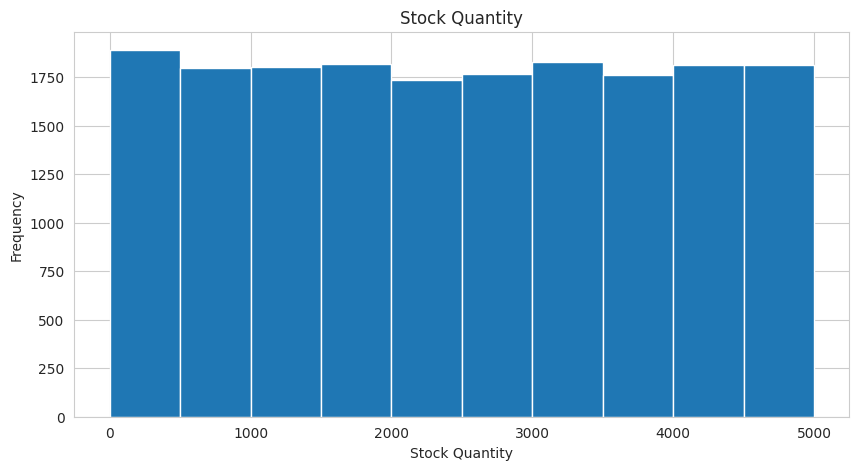

In [15]:
# histogram
# What is the distribution of stock quantity
plt.figure(figsize=(10,5))
plt.hist(df["StockQuantity"])
plt.title("Stock Quantity")
plt.xlabel("Stock Quantity")
plt.ylabel("Frequency")
plt.show()

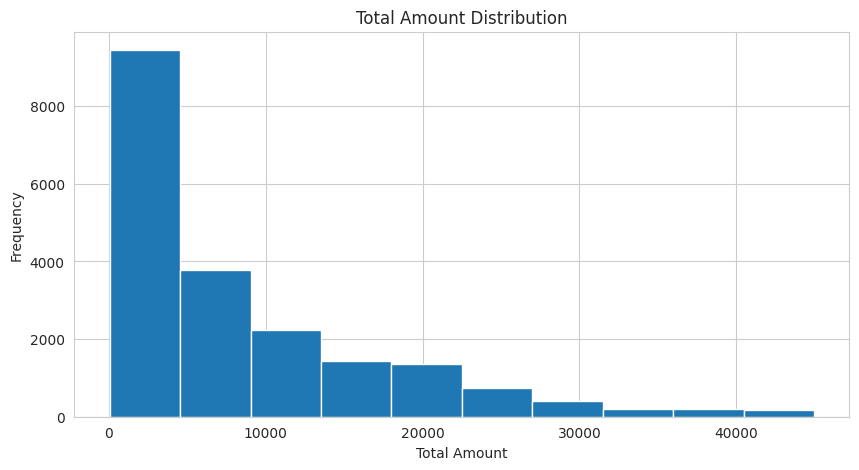

In [16]:
# What is the distribution of prescription amounts
plt.figure(figsize=(10,5))
plt.hist(df["TotalAmount"])
plt.title("Total Amount Distribution")
plt.xlabel("Total Amount")
plt.ylabel("Frequency")
plt.show()

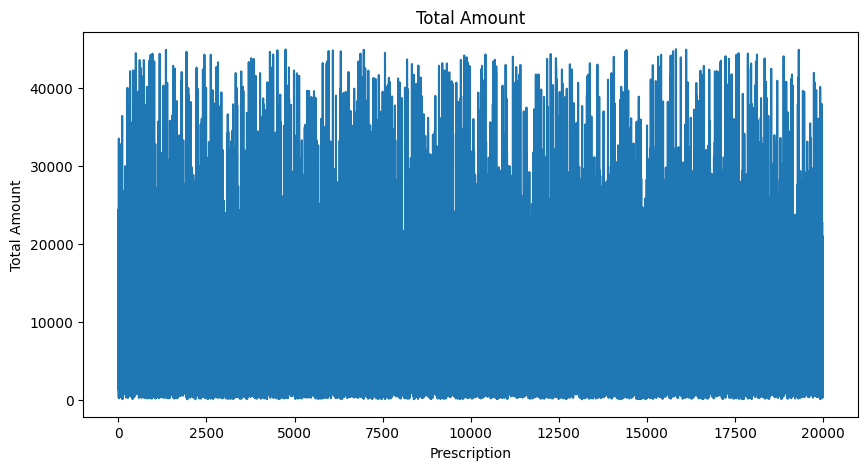

In [ ]:
# line plot
# How does the total amount change across prescriptions
plt.figure(figsize=(10,5))
plt.plot(df["TotalAmount"])
plt.title("Total Amount")
plt.xlabel("Prescription")
plt.ylabel("Total Amount")
plt.show()

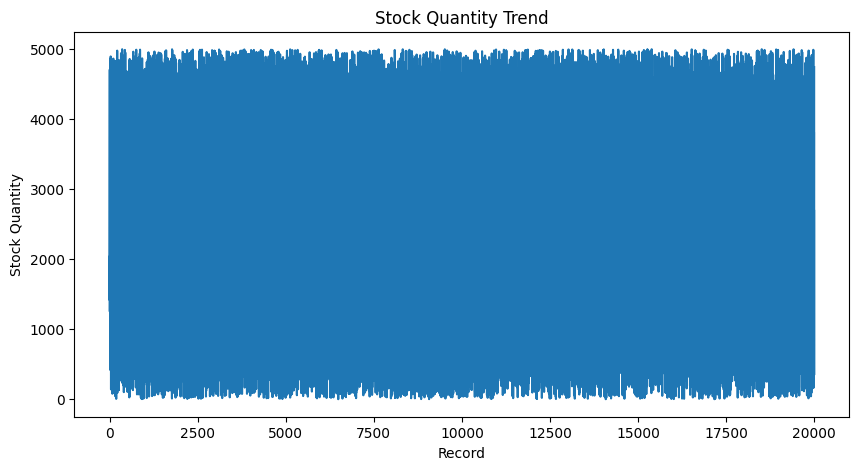

In [ ]:
# How does stock quantity vary across the records
plt.figure(figsize=(10,5))
plt.plot(df["StockQuantity"])
plt.title("Stock Quantity Trend")
plt.xlabel("Record")
plt.ylabel("Stock Quantity")
plt.show()

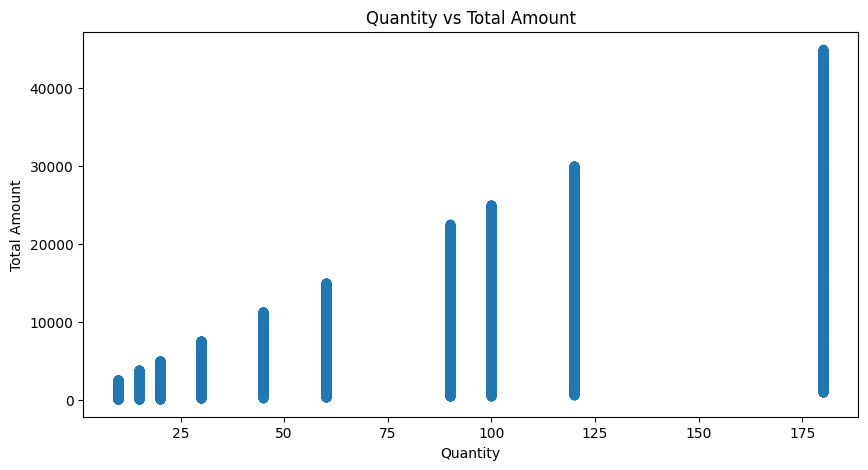

In [ ]:
# Scatter Plot — Quantity vs Total Amount
# Is there a relationship between quantity and total amount
plt.figure(figsize=(10,5))
plt.scatter(df["Quantity"], df["TotalAmount"])
plt.title("Quantity vs Total Amount")
plt.xlabel("Quantity")
plt.ylabel("Total Amount")
plt.show()

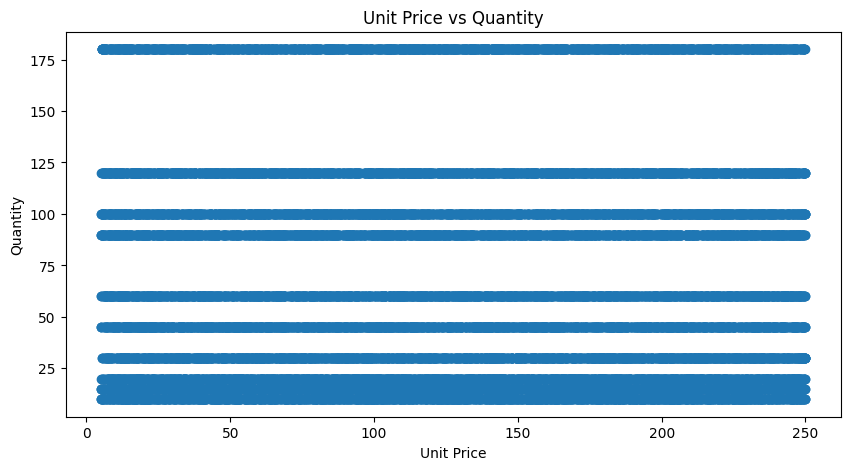

In [ ]:
# Is there a relationship between unit price and quantity
plt.figure(figsize=(10,5))
plt.scatter(df["UnitPrice"], df["Quantity"])
plt.title("Unit Price vs Quantity")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.show()

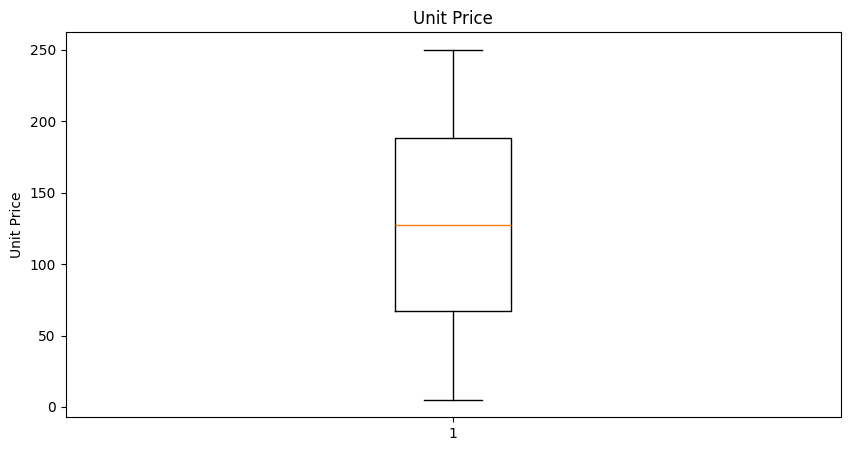

In [ ]:
# box plot
# What is the spread of medication unit prices
plt.figure(figsize=(10,5))
plt.boxplot(df["UnitPrice"].dropna())
plt.title("Unit Price")
plt.ylabel("Unit Price")
plt.show()

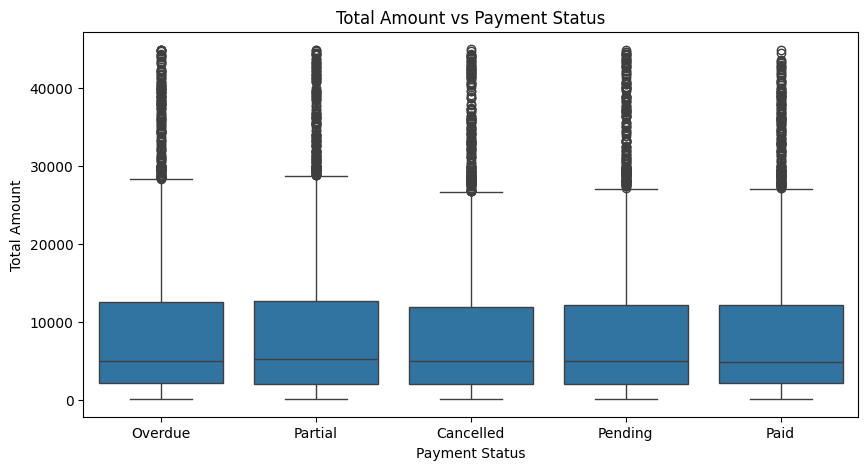

In [ ]:
# How does the total amount vary by payment status
plt.figure(figsize=(10,5))
sns.boxplot(x="PaymentStatus", y="TotalAmount", data=df)
plt.title("Total Amount vs Payment Status")
plt.xlabel("Payment Status")
plt.ylabel("Total Amount")
plt.show()

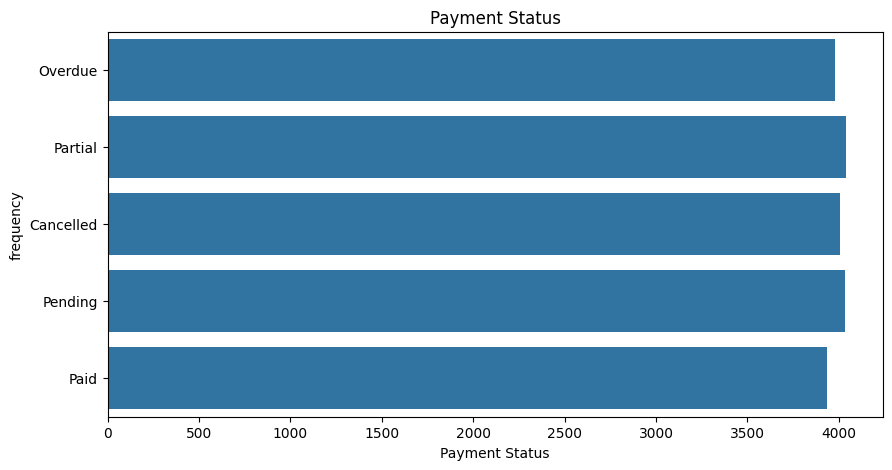

In [ ]:
# bar plt
# What is the distribution of payment status
plt.figure(figsize=(10,5))
sns.countplot(df["PaymentStatus"])
plt.title("Payment Status")
plt.xlabel("Payment Status")
plt.ylabel("frequency")
plt.show()

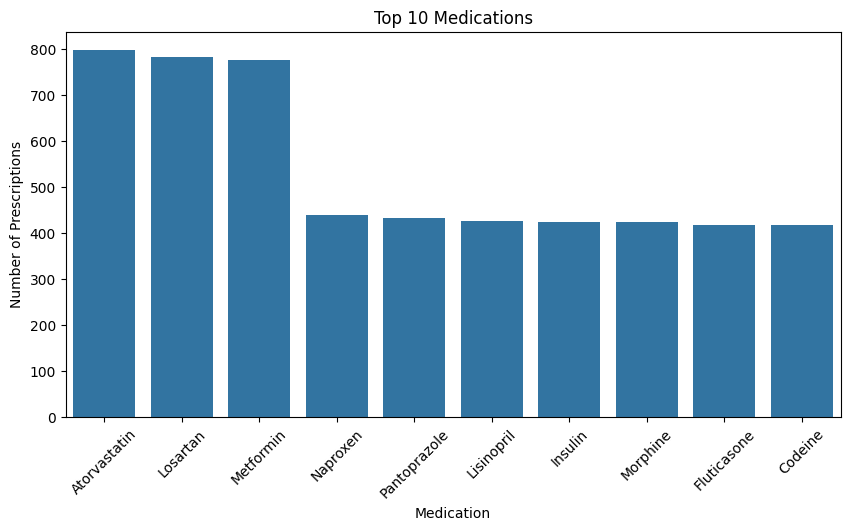

In [ ]:
# Which medications are prescribed most frequently
plt.figure(figsize=(10,5))
sns.countplot(x="MedicationName", data=df, order=df["MedicationName"].value_counts().head(10).index)
plt.title("Top 10 Medications")
plt.xlabel("Medication")
plt.ylabel("Number of Prescriptions")
plt.xticks(rotation=45)
plt.show()

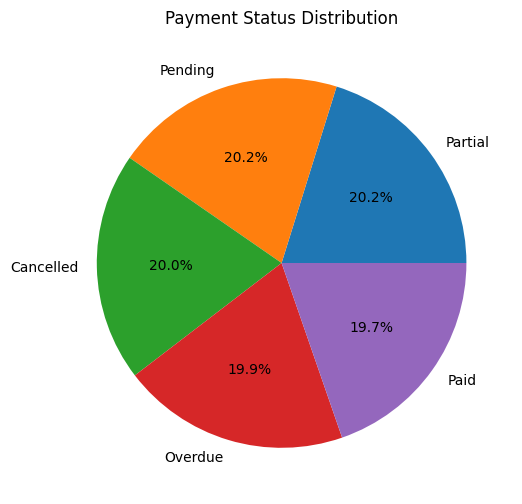

In [ ]:
# pie chart
# What is the distribution of patients based on their payment status
plt.figure(figsize=(8,6))
payment_counts = df["PaymentStatus"].value_counts()
plt.pie(payment_counts,
        labels=payment_counts.index,
        autopct="%1.1f%%")
plt.title("Payment Status Distribution")
plt.show()

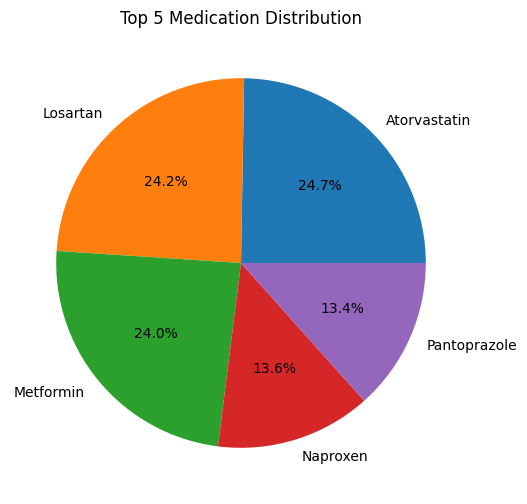

In [ ]:
# What is the distribution of prescriptions among different medications
plt.figure(figsize=(8,6))
medication_counts = df["MedicationName"].value_counts().head(5)
plt.pie(medication_counts,
        labels=medication_counts.index,
        autopct="%1.1f%%")
plt.title("Top 5 Medication Distribution")
plt.show()


In [18]:
import pandas as pd
import numpy as np

df = pd.read_csv("meditrack_dataset.csv")

cleaned_df = df.copy()

cleaned_df["PatientName"] = cleaned_df["PatientName"].fillna("Unknown")
cleaned_df["Phone"] = cleaned_df["Phone"].fillna("Not Available")
cleaned_df["DOB"] = cleaned_df["DOB"].fillna("Not Available")
cleaned_df["StockQuantity"] = cleaned_df["StockQuantity"].fillna(
    cleaned_df["StockQuantity"].median()
)
cleaned_df["ExpiryDate"] = cleaned_df["ExpiryDate"].fillna("Not Available")

cleaned_df = cleaned_df.drop_duplicates()

cleaned_df["Quantity"] = pd.to_numeric(
    cleaned_df["Quantity"], errors="coerce"
)
cleaned_df["StockQuantity"] = pd.to_numeric(
    cleaned_df["StockQuantity"], errors="coerce"
)
cleaned_df["UnitPrice"] = pd.to_numeric(
    cleaned_df["UnitPrice"], errors="coerce"
)
cleaned_df["TotalAmount"] = pd.to_numeric(
    cleaned_df["TotalAmount"], errors="coerce"
)

cleaned_df["DateIssued"] = pd.to_datetime(
    cleaned_df["DateIssued"], errors="coerce"
)
cleaned_df["ExpiryDate"] = pd.to_datetime(
    cleaned_df["ExpiryDate"], errors="coerce"
)

print("cleaned dataset shape:", cleaned_df.shape)

cleaned dataset shape: (20000, 15)


/tmp/ipykernel_7404/2822052183.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cleaned_df["ExpiryDate"] = pd.to_datetime(


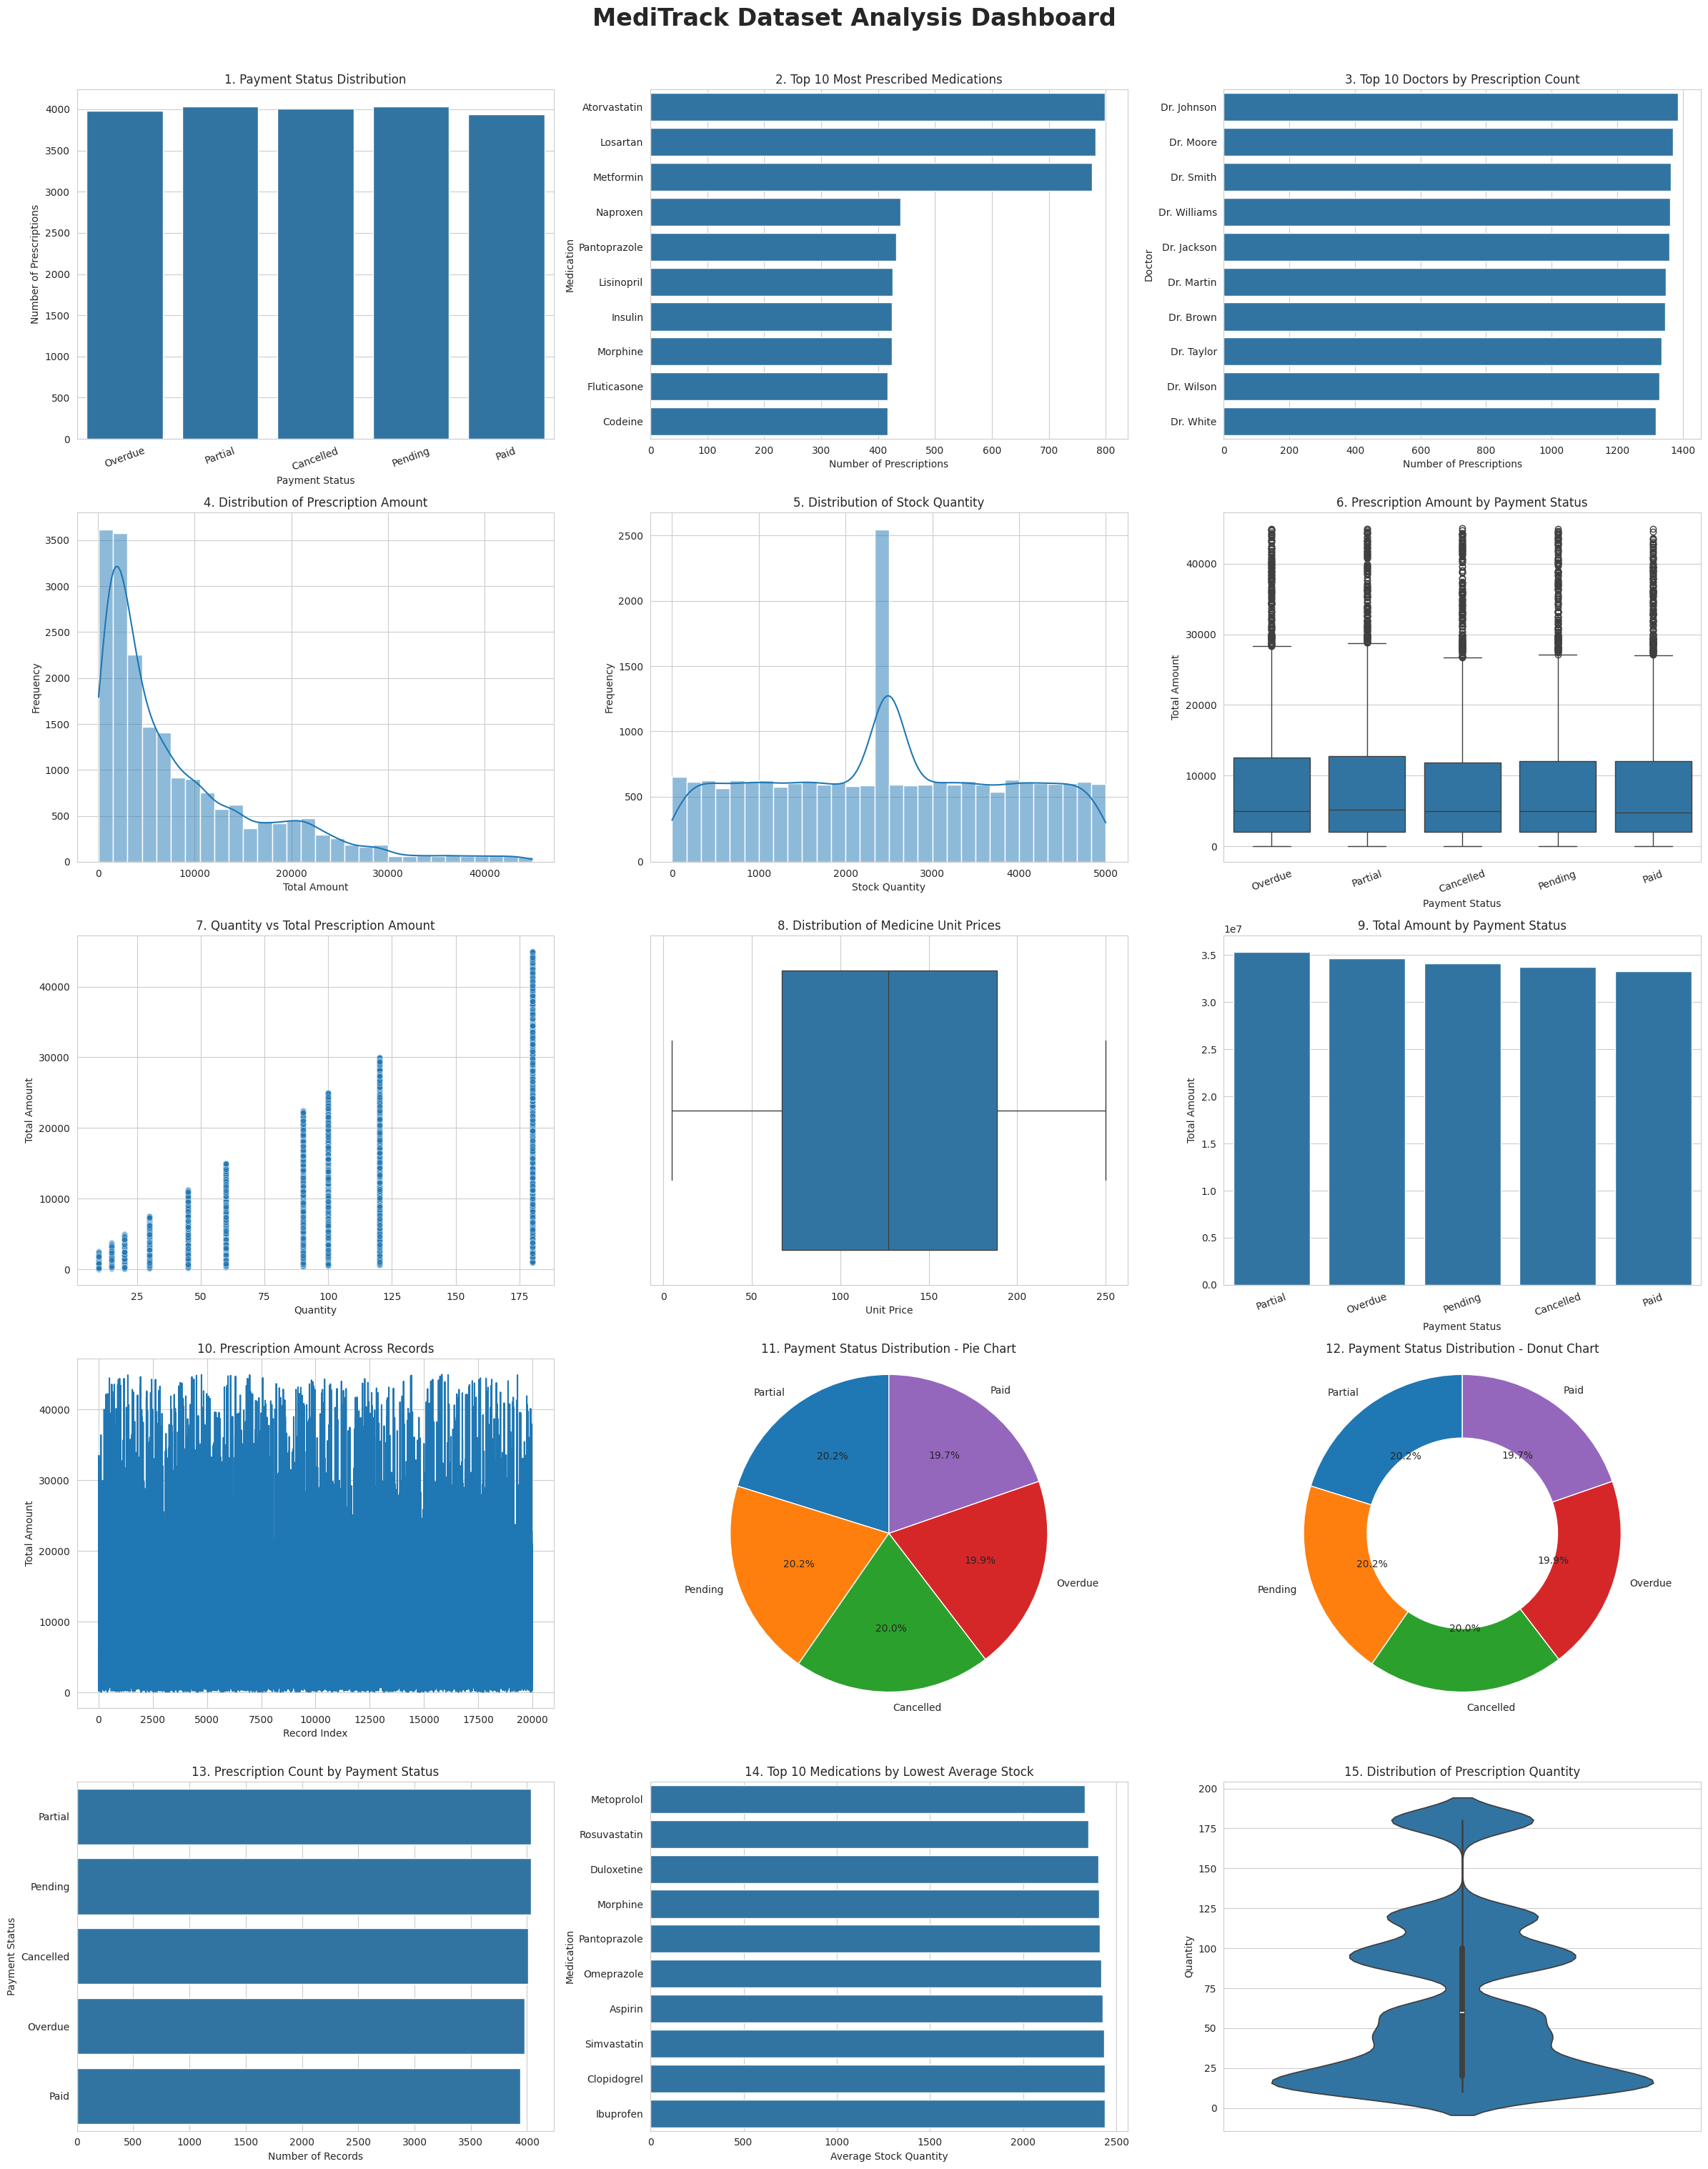

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_style("whitegrid")

fig, axes = plt.subplots(5, 3, figsize=(24, 30))
axes = axes.flatten()

# 1. Payment status distribution - Count Plot
sns.countplot(x="PaymentStatus", data=cleaned_df, ax=axes[0])
axes[0].set_title("1. Payment Status Distribution")
axes[0].set_xlabel("Payment Status")
axes[0].set_ylabel("Number of Prescriptions")
axes[0].tick_params(axis="x", rotation=20)

# 2. Top 10 medications - Bar Chart
top_medications = cleaned_df["MedicationName"].value_counts().head(10)
sns.barplot(x=top_medications.values, y=top_medications.index, ax=axes[1])
axes[1].set_title("2. Top 10 Most Prescribed Medications")
axes[1].set_xlabel("Number of Prescriptions")
axes[1].set_ylabel("Medication")

# 3. Top 10 doctors - Horizontal Bar Chart
top_doctors = cleaned_df["DoctorName"].value_counts().head(10)
sns.barplot(x=top_doctors.values, y=top_doctors.index, ax=axes[2])
axes[2].set_title("3. Top 10 Doctors by Prescription Count")
axes[2].set_xlabel("Number of Prescriptions")
axes[2].set_ylabel("Doctor")

# 4. Prescription amount distribution - Histogram
sns.histplot(
    cleaned_df["TotalAmount"].dropna(),
    bins=30, kde=True, ax=axes[3]
)
axes[3].set_title("4. Distribution of Prescription Amount")
axes[3].set_xlabel("Total Amount")
axes[3].set_ylabel("Frequency")

# 5. Stock quantity distribution - Histogram
sns.histplot(
    cleaned_df["StockQuantity"].dropna(),
    bins=30, kde=True, ax=axes[4]
)
axes[4].set_title("5. Distribution of Stock Quantity")
axes[4].set_xlabel("Stock Quantity")
axes[4].set_ylabel("Frequency")

# 6. Prescription amount by payment status - Box Plot
sns.boxplot(
    x="PaymentStatus", y="TotalAmount",
    data=cleaned_df, ax=axes[5]
)
axes[5].set_title("6. Prescription Amount by Payment Status")
axes[5].set_xlabel("Payment Status")
axes[5].set_ylabel("Total Amount")
axes[5].tick_params(axis="x", rotation=20)

# 7. Quantity vs total amount - Scatter Plot
sns.scatterplot(
    x="Quantity", y="TotalAmount",
    data=cleaned_df, ax=axes[6], alpha=0.6
)
axes[6].set_title("7. Quantity vs Total Prescription Amount")
axes[6].set_xlabel("Quantity")
axes[6].set_ylabel("Total Amount")

# 8. Unit price distribution - Box Plot
sns.boxplot(x=cleaned_df["UnitPrice"].dropna(), ax=axes[7])
axes[7].set_title("8. Distribution of Medicine Unit Prices")
axes[7].set_xlabel("Unit Price")

# 9. Revenue by payment status - Bar Chart
revenue_by_status = (
    cleaned_df.groupby("PaymentStatus")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
)
sns.barplot(
    x=revenue_by_status.index,
    y=revenue_by_status.values,
    ax=axes[8]
)
axes[8].set_title("9. Total Amount by Payment Status")
axes[8].set_xlabel("Payment Status")
axes[8].set_ylabel("Total Amount")
axes[8].tick_params(axis="x", rotation=20)

# 10. Prescription amount across records - Line Plot
axes[9].plot(cleaned_df.index, cleaned_df["TotalAmount"])
axes[9].set_title("10. Prescription Amount Across Records")
axes[9].set_xlabel("Record Index")
axes[9].set_ylabel("Total Amount")

# 11. Payment status - Pie Chart
payment_counts = cleaned_df["PaymentStatus"].value_counts().dropna()
axes[10].pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[10].set_title("11. Payment Status Distribution - Pie Chart")
axes[10].axis("equal")

# 12. Payment status - Donut Chart
axes[11].pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)
axes[11].set_title("12. Payment Status Distribution - Donut Chart")
axes[11].axis("equal")

# 13. Prescription count by payment status - Horizontal Bar Chart
sns.barplot(
    x=payment_counts.values,
    y=payment_counts.index,
    ax=axes[12]
)
axes[12].set_title("13. Prescription Count by Payment Status")
axes[12].set_xlabel("Number of Records")
axes[12].set_ylabel("Payment Status")

# 14. Medication stock levels - Top 10 lowest average stock
lowest_stock = (
    cleaned_df.groupby("MedicationName")["StockQuantity"]
    .mean()
    .nsmallest(10)
)
sns.barplot(
    x=lowest_stock.values,
    y=lowest_stock.index,
    ax=axes[13]
)
axes[13].set_title("14. Top 10 Medications by Lowest Average Stock")
axes[13].set_xlabel("Average Stock Quantity")
axes[13].set_ylabel("Medication")

# 15. Quantity distribution - Violin Plot
sns.violinplot(
    y=cleaned_df["Quantity"].dropna(),
    ax=axes[14]
)
axes[14].set_title("15. Distribution of Prescription Quantity")
axes[14].set_ylabel("Quantity")

# Overall dashboard title
fig.suptitle(
    "MediTrack Dataset Analysis Dashboard",
    fontsize=24,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

In [ ]:
print("cleaned_df exists:", "cleaned_df" in globals())

if "cleaned_df" in globals():
    print("shape:", cleaned_df.shape)
    print("columns:")
    print(cleaned_df.columns.tolist())

cleaned_df exists: True
shape: (20000, 15)
columns:
['PatientID', 'PatientName', 'DOB', 'Phone', 'PrescriptionID', 'MedicationName', 'Dosage', 'Quantity', 'DoctorName', 'DateIssued', 'ExpiryDate', 'StockQuantity', 'UnitPrice', 'TotalAmount', 'PaymentStatus']


In [ ]:
plt.savefig(
    "meditrack_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>